# ShopSmart - Content-Based Filtering

## 1. TF-IDF and Cosine Similarity

This notebook implements a content-based recommendation
system using product metadata.

The model uses:
- Product titles
- Categories
- Features
- Descriptions

We represent products using TF-IDF and compute
their similarity using cosine similarity.

In [1]:
import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

PROCESSED_DIR = Path("../data/processed")

products = pd.read_json(
    PROCESSED_DIR / "products_preprocessed.jsonl",
    lines=True
)

train = pd.read_csv(PROCESSED_DIR / "train.csv")
validation = pd.read_csv(PROCESSED_DIR / "validation.csv")
test = pd.read_csv(PROCESSED_DIR / "test.csv")

print("Products:", products.shape)
print("Train:", train.shape)

display(products[["parent_asin", "title", "content"]].head())

Products: (2000, 13)
Train: (132836, 4)


,parent_asin,title,content
0,B07RWDZ3HG,SilverStone Technology SST-FF121 120mm Ultra F...,SilverStone Technology SST-FF121 120mm Ultra F...
1,B09SJ9192T,"SAMSUNG 23.5” CF396 Curved Computer Monitor, A...","SAMSUNG 23.5” CF396 Curved Computer Monitor, A..."
2,B07FTSFGXH,"Cat6 Ethernet Cable, 12 Feet (2 Pack) LAN, utp...","Cat6 Ethernet Cable, 12 Feet (2 Pack) LAN, utp..."
3,B00RVFCFI2,ExpertPower XP-669 7.5-Inch Dual Band SMA-F An...,ExpertPower XP-669 7.5-Inch Dual Band SMA-F An...
4,B0C49KQRX4,Tzowla Travel Laptop Backpack Water Resistant ...,Tzowla Travel Laptop Backpack Water Resistant ...


In [2]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=10000,
    min_df=2,
    max_df=0.95
)

tfidf_matrix = tfidf.fit_transform(
    products["content"].fillna("")
)

print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (2000, 9386)


In [3]:
# Map each product ID to its row in the TF-IDF matrix
product_index = pd.Series(
    products.index,
    index=products["parent_asin"]
)

def recommend_similar_products(product_id, top_n=5):

    if product_id not in product_index:
        print("Product not found!")
        return pd.DataFrame()

    idx = product_index[product_id]

    # Compute cosine similarity with all products
    similarity_scores = cosine_similarity(
        tfidf_matrix[idx],
        tfidf_matrix
    ).flatten()

    # Exclude the selected product itself
    similarity_scores[idx] = -1

    # Get the most similar products
    top_indices = np.argsort(
        similarity_scores
    )[::-1][:top_n]

    recommendations = products.iloc[
        top_indices
    ][["parent_asin", "title", "main_category"]].copy()

    recommendations["similarity_score"] = (
        similarity_scores[top_indices]
    )

    return recommendations

In [4]:
# Example: Samsung Curved Monitor
product_id = "B09SJ9192T"

selected_product = products[
    products["parent_asin"] == product_id
]

print("Selected product:")
display(
    selected_product[
        ["title", "main_category"]
    ]
)

print("\nTop 5 similar products:")
display(
    recommend_similar_products(
        product_id,
        top_n=5
    )
)

Selected product:


,title,main_category
1,"SAMSUNG 23.5” CF396 Curved Computer Monitor, A...",Computers



Top 5 similar products:


,parent_asin,title,main_category,similarity_score
1704,B0C2J1HF4Z,"BenQ GL2780 Gaming Monitor 27"" FHD 1920x1080p ...",Computers,0.316340
1114,B0BPL23TRN,SAMSUNG 49-Inch CHG90 144Hz Curved Gaming Moni...,Computers,0.287437
415,B0C2WWCBSG,"Acer SB242Y EBI 23.8"" Full HD (1920 x 1080) IP...",Computers,0.259239
146,B0BFM2GP2B,"Acer R241Y Bbix 23.8"" Full HD (1920 x 1080) IP...",Computers,0.248019
1835,B08BF4CZSV,HP 24mh FHD Monitor - Computer Monitor with 23...,Computers,0.232154


## 2. Personalized Content-Based Recommendations

We build a user profile from products rated 4 or 5 stars
in the training dataset.

The system recommends unseen products whose content
is most similar to the user's preferences.

In [5]:
def recommend_for_user(user_id, top_n=5):

    # User's training history
    history = train[train["user_id"] == user_id]

    if history.empty:
        return pd.DataFrame()

    # Products positively rated by the user
    liked = history[history["rating"] >= 4]

    if liked.empty:
        return pd.DataFrame()

    liked_indices = [
        product_index[asin]
        for asin in liked["parent_asin"]
        if asin in product_index
    ]

    if not liked_indices:
        return pd.DataFrame()

    # Build user profile from liked products
    user_profile = np.asarray(
        tfidf_matrix[liked_indices].mean(axis=0)
    )

    # Compare user profile with all products
    scores = cosine_similarity(
        user_profile,
        tfidf_matrix
    ).flatten()

    # Exclude products already rated in training
    seen_products = set(history["parent_asin"])

    for asin in seen_products:
        if asin in product_index:
            scores[product_index[asin]] = -1

    # Get top recommendations
    top_indices = np.argsort(scores)[::-1][:top_n]

    recommendations = products.iloc[top_indices][
        ["parent_asin", "title", "main_category"]
    ].copy()

    recommendations["similarity_score"] = scores[top_indices]

    return recommendations

In [6]:
# Select a user who liked at least 3 products
positive_counts = (
    train[train["rating"] >= 4]
    .groupby("user_id")
    .size()
)

user_id = positive_counts[
    positive_counts >= 3
].index[0]

print("Selected user:", user_id)

print("\nProducts liked by this user:")
display(
    train[
        (train["user_id"] == user_id) &
        (train["rating"] >= 4)
    ].merge(
        products[["parent_asin", "title"]],
        on="parent_asin"
    )[["title", "rating"]].head(10)
)

print("\nTop 5 personalized recommendations:")
display(recommend_for_user(user_id, top_n=5))

Selected user: AE22LPCN47WUTHSG67R6SKN4A4MQ

Products liked by this user:


,title,rating
0,D-Link Wi-Fi Camera with Remote Viewing (DCS-9...,4.0
1,Cooler Master Hyper 212 EVO V2 CPU Air Cooler ...,4.0
2,"Silencio FP120 PWM 2400, 120mm cooling fan, Wh...",4.0
3,D-Link Day & Night Wi-Fi Camera with Remote Vi...,5.0
4,Corsair Air Series AF120 LED Quiet Edition Hig...,5.0
5,1ft (0.3M) 18AWG (Power Extension Cord) Power ...,5.0
6,Amazon Basics 4 Port USB to USB 3.0 Hub with 5...,5.0
7,SABRENT Aluminum USB External Stereo Sound Ada...,5.0
8,Amazon Basics Toslink Digital Optical Audio Ca...,5.0
9,Amazon Basics USB-A to Mini USB 2.0 Fast Charg...,5.0



Top 5 personalized recommendations:


,parent_asin,title,main_category,similarity_score
1170,B08XMDNVX6,"Fire TV Cube, Hands-free streaming device with...",Amazon Devices,0.468471
1730,B0791T9CV7,"Fire TV Cube (1st Gen), hands-free with Alexa ...",Amazon Devices,0.451593
1739,B01NBTFNVA,"Fire TV Cube (1st Gen), hands-free with Alexa ...",Amazon Devices,0.445756
1958,B07ZZVX1F2,Fire TV Stick with Alexa Voice Remote (include...,Amazon Devices,0.438526
1397,B07GZFM1ZM,Fire TV Stick 4K streaming device with Alexa V...,Amazon Devices,0.434384


## 3. Content-Based Model Evaluation

We evaluate personalized recommendations using the validation set.

A product is considered relevant if the user rated it
4 or 5 stars.

Evaluation metrics:
- Precision@10
- Recall@10
- Hit Rate@10

In [7]:
# Relevant validation interactions
validation_positive = validation[
    validation["rating"] >= 4
].copy()

# Keep users with at least one positive training rating
users_with_positive_history = set(
    train.loc[train["rating"] >= 4, "user_id"]
)

validation_positive = validation_positive[
    validation_positive["user_id"].isin(
        users_with_positive_history
    )
]

# Select a reproducible sample
eval_users = validation_positive.sample(
    n=min(300, len(validation_positive)),
    random_state=42
)

print("Total eligible users:", len(validation_positive))
print("Users selected for evaluation:", len(eval_users))

Total eligible users: 6122
Users selected for evaluation: 300


In [8]:
K = 10

precision_scores = []
recall_scores = []
hit_scores = []

for _, row in eval_users.iterrows():

    user_id = row["user_id"]
    relevant_product = row["parent_asin"]

    recommendations = recommend_for_user(
        user_id,
        top_n=K
    )

    recommended_ids = set(
        recommendations["parent_asin"]
    )

    hit = int(relevant_product in recommended_ids)

    precision_scores.append(hit / K)
    recall_scores.append(hit)
    hit_scores.append(hit)

print("Content-Based Evaluation")
print("------------------------")

print(f"Precision@{K}: {np.mean(precision_scores):.4f}")
print(f"Recall@{K}: {np.mean(recall_scores):.4f}")
print(f"Hit Rate@{K}: {np.mean(hit_scores):.4f}")

Content-Based Evaluation
------------------------
Precision@10: 0.0023
Recall@10: 0.0233
Hit Rate@10: 0.0233


In [9]:
recommended_products = set()

for user_id in eval_users["user_id"]:

    recommendations = recommend_for_user(
        user_id,
        top_n=K
    )

    recommended_products.update(
        recommendations["parent_asin"]
    )

catalog_coverage = (
    len(recommended_products) / len(products)
)

print("Unique recommended products:",
      len(recommended_products))

print(f"Catalog Coverage: {catalog_coverage:.2%}")

Unique recommended products: 735
Catalog Coverage: 36.75%


## 4. Popularity-Based Baseline

We implement a simple popularity-based recommender
using only training interactions.

The baseline recommends the most frequently rated
products that the user has not previously rated.

We compare its performance with our Content-Based model.

In [15]:
# Calculate product popularity using training data only
product_popularity = (
    train.groupby("parent_asin")
    .size()
    .sort_values(ascending=False)
)

popular_products = product_popularity.index.tolist()

# Precompute user histories
user_seen = (
    train.groupby("user_id")["parent_asin"]
    .agg(set)
    .to_dict()
)

def recommend_popular(user_id, top_n=10):

    seen = user_seen.get(user_id, set())

    recommendations = [
        asin for asin in popular_products
        if asin not in seen
    ][:top_n]

    return recommendations

In [12]:
K = 10

baseline_hits = []

for _, row in eval_users.iterrows():

    user_id = row["user_id"]
    relevant_product = row["parent_asin"]

    recommendations = recommend_popular(
        user_id, top_n=K
    )

    hit = int(relevant_product in recommendations)

    baseline_hits.append(hit)

baseline_hit_rate = np.mean(baseline_hits)
baseline_precision = baseline_hit_rate / K

print("Popularity Baseline Evaluation")
print("-----------------------------")
print(f"Precision@{K}: {baseline_precision:.4f}")
print(f"Recall@{K}: {baseline_hit_rate:.4f}")
print(f"Hit Rate@{K}: {baseline_hit_rate:.4f}")

Popularity Baseline Evaluation
-----------------------------
Precision@10: 0.0047
Recall@10: 0.0467
Hit Rate@10: 0.0467


In [13]:
comparison = pd.DataFrame({
    "Model": ["Content-Based TF-IDF", "Popularity Baseline"],
    "Precision@10": [
        np.mean(precision_scores),
        baseline_precision
    ],
    "Recall@10": [
        np.mean(recall_scores),
        baseline_hit_rate
    ],
    "Hit Rate@10": [
        np.mean(hit_scores),
        baseline_hit_rate
    ]
})

display(comparison)

,Model,Precision@10,Recall@10,Hit Rate@10
0,Content-Based TF-IDF,0.002333,0.023333,0.023333
1,Popularity Baseline,0.004667,0.046667,0.046667


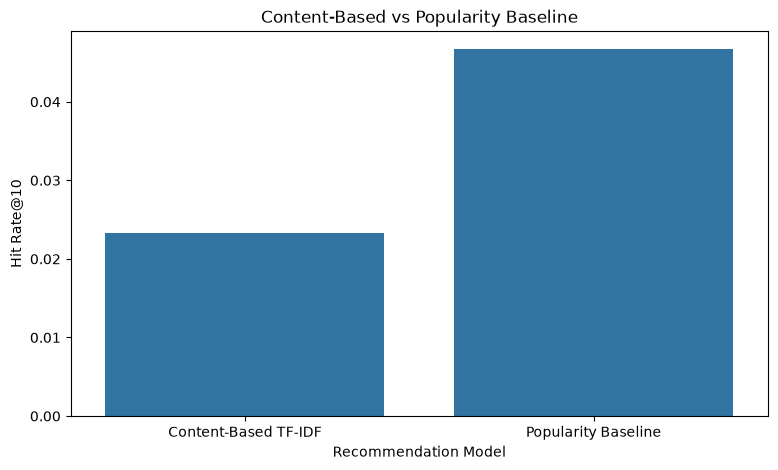

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Hit Rate@10"
)

plt.title("Content-Based vs Popularity Baseline")
plt.ylabel("Hit Rate@10")
plt.xlabel("Recommendation Model")

plt.show()

## 5. Extended Validation - 1000 Users

We evaluate Content-Based TF-IDF and the Popularity Baseline
on 1,000 validation users.

The evaluation uses the same user-selection protocol and
random seed as Collaborative Filtering.

In [16]:
# Same validation sample as Collaborative Filtering
eval_users_1000 = validation_positive.sample(
    n=min(1000, len(validation_positive)),
    random_state=42
)

K = 10

content_hits = []
content_recommended = set()

for _, row in eval_users_1000.iterrows():

    recommendations = recommend_for_user(
        row["user_id"],
        top_n=K
    )

    recommended_ids = set(recommendations["parent_asin"])

    content_hits.append(
        int(row["parent_asin"] in recommended_ids)
    )

    content_recommended.update(recommended_ids)

content_hit_rate = np.mean(content_hits)
content_coverage = len(content_recommended) / len(products)

print("Content-Based TF-IDF")
print(f"Precision@10: {content_hit_rate / K:.4f}")
print(f"Recall@10: {content_hit_rate:.4f}")
print(f"Hit Rate@10: {content_hit_rate:.4f}")
print(f"Coverage: {content_coverage:.2%}")

Content-Based TF-IDF
Precision@10: 0.0030
Recall@10: 0.0300
Hit Rate@10: 0.0300
Coverage: 49.65%


In [17]:
baseline_hits = []
baseline_recommended = set()

for _, row in eval_users_1000.iterrows():

    recommendations = recommend_popular(
        row["user_id"],
        top_n=K
    )

    baseline_hits.append(
        int(row["parent_asin"] in recommendations)
    )

    baseline_recommended.update(recommendations)

baseline_hit_rate = np.mean(baseline_hits)
baseline_coverage = len(baseline_recommended) / len(products)

print("Popularity Baseline")
print(f"Precision@10: {baseline_hit_rate / K:.4f}")
print(f"Recall@10: {baseline_hit_rate:.4f}")
print(f"Hit Rate@10: {baseline_hit_rate:.4f}")
print(f"Coverage: {baseline_coverage:.2%}")

Popularity Baseline
Precision@10: 0.0040
Recall@10: 0.0400
Hit Rate@10: 0.0400
Coverage: 0.80%


In [18]:
comparison_extended = pd.DataFrame({
    "Model": [
        "Content-Based TF-IDF",
        "Popularity Baseline"
    ],
    "Precision@10": [
        content_hit_rate / K,
        baseline_hit_rate / K
    ],
    "Hit Rate@10": [
        content_hit_rate,
        baseline_hit_rate
    ],
    "Coverage": [
        content_coverage,
        baseline_coverage
    ]
})

display(comparison_extended)

,Model,Precision@10,Hit Rate@10,Coverage
0,Content-Based TF-IDF,0.003,0.03,0.4965
1,Popularity Baseline,0.004,0.04,0.0080


In [19]:
comparison_extended.to_csv(
    PROCESSED_DIR / "content_popularity_validation.csv",
    index=False
)

print("Extended validation results saved!")

Extended validation results saved!


## 6. Final Test Evaluation

We evaluate Content-Based TF-IDF and the Popularity Baseline
using the same test sample as the Collaborative Filtering models.

Models and hyperparameters remain unchanged after validation.

In [20]:
eval_test = pd.read_csv(
    PROCESSED_DIR / "test_users_sample.csv"
)

print("Test users:", len(eval_test))
print("Unique users:", eval_test["user_id"].nunique())

display(eval_test.head())

Test users: 1000
Unique users: 1000


,user_id,parent_asin,rating
0,AHREMBWVXSKMB6RGI5XQHI7X22OA,B0C1JGLV8T,5.0
1,AGAGFXOG2KRKWD4VK6UDQDBH2NSA,B08KY684PB,5.0
2,AFTBPWW32753SLLKOBCXDL267NYA,B00650P2ZC,5.0
3,AFFU7MCUYCZCDWNRLM2S46JEI2EA,B0B933F7G2,5.0
4,AH3OZNHZ4NAQC6F5LT3NOLPDYH3A,B0BZ5C5QNB,4.0


In [21]:
K = 10

content_hits = []
content_recommended = set()

for _, row in eval_test.iterrows():

    recommendations = recommend_for_user(
        row["user_id"],
        top_n=K
    )

    recommended_ids = set(
        recommendations["parent_asin"]
    )

    hit = int(row["parent_asin"] in recommended_ids)

    content_hits.append(hit)
    content_recommended.update(recommended_ids)

content_test_hit_rate = np.mean(content_hits)
content_test_coverage = (
    len(content_recommended) / len(products)
)

print("Content-Based - Test Results")
print(f"Precision@10: {content_test_hit_rate / K:.4f}")
print(f"Hit Rate@10: {content_test_hit_rate:.4f}")
print(f"Coverage: {content_test_coverage:.2%}")

Content-Based - Test Results
Precision@10: 0.0018
Hit Rate@10: 0.0180
Coverage: 51.30%


In [22]:
baseline_hits = []
baseline_recommended = set()

for _, row in eval_test.iterrows():

    recommendations = recommend_popular(
        row["user_id"],
        top_n=K
    )

    hit = int(row["parent_asin"] in recommendations)

    baseline_hits.append(hit)
    baseline_recommended.update(recommendations)

baseline_test_hit_rate = np.mean(baseline_hits)
baseline_test_coverage = (
    len(baseline_recommended) / len(products)
)

print("Popularity - Test Results")
print(f"Precision@10: {baseline_test_hit_rate / K:.4f}")
print(f"Hit Rate@10: {baseline_test_hit_rate:.4f}")
print(f"Coverage: {baseline_test_coverage:.2%}")

Popularity - Test Results
Precision@10: 0.0018
Hit Rate@10: 0.0180
Coverage: 0.95%


In [23]:
content_popularity_test = pd.DataFrame({
    "Model": [
        "Content-Based TF-IDF",
        "Popularity Baseline"
    ],
    "Precision@10": [
        content_test_hit_rate / K,
        baseline_test_hit_rate / K
    ],
    "Hit Rate@10": [
        content_test_hit_rate,
        baseline_test_hit_rate
    ],
    "Coverage": [
        content_test_coverage,
        baseline_test_coverage
    ]
})

display(content_popularity_test)

content_popularity_test.to_csv(
    PROCESSED_DIR / "content_popularity_test_results.csv",
    index=False
)

print("Test results saved successfully!")

,Model,Precision@10,Hit Rate@10,Coverage
0,Content-Based TF-IDF,0.0018,0.018,0.5130
1,Popularity Baseline,0.0018,0.018,0.0095


Test results saved successfully!
